Импорты, настройки и пробный запрос к API

In [ ]:
import time
import requests
import pandas as pd

BASE_URL = "https://musicbrainz.org/ws/2/release"
HEADERS = {
    "User-Agent": "PhonkEvolutionResearch/1.0 (https://github.com/Kuzmichqq/dh_hw_scraping)",
    "Connection": "close",
}

# Пробный запрос для проверки доступности API и общего числа записей в каталоге
probe_params = {"query": "tag:phonk", "fmt": "json", "limit": 1, "offset": 0}
probe_resp = requests.get(BASE_URL, params=probe_params, headers=HEADERS, timeout=20)
probe_resp.raise_for_status()

total_in_catalog = probe_resp.json().get("count", 0)
print(f"Статус API: {probe_resp.status_code}")
print(f"Всего релизов с тегом 'phonk' в базе MusicBrainz: {total_in_catalog}")
time.sleep(1.5)

Статус API: 200
Всего релизов с тегом 'phonk' в базе MusicBrainz: 731


Функции запроса (с повторами при сбоях) и парсинга записи

In [3]:
def fetch_releases_page(query, offset, limit=50):
    """Запрашивает одну страницу релизов из MusicBrainz API с обработкой ошибок."""
    params = {
        "query": query,
        "fmt": "json",
        "limit": limit,
        "offset": offset,
    }

    for attempt in range(5):
        try:
            response = requests.get(BASE_URL, params=params, headers=HEADERS, timeout=30)

            if response.status_code == 503:
                wait_time = 3 * (attempt + 1)
                print(f"  Сервер занят (503) на offset={offset}, пауза {wait_time} сек...")
                time.sleep(wait_time)
                continue

            if response.status_code == 400:
                print(f"  Достигнут лимит пагинации (400) на offset={offset}.")
                return "STOP"

            response.raise_for_status()
            return response.json()

        except requests.RequestException as e:
            wait_time = 3 * (attempt + 1)
            print(f"  Сбой соединения (попытка {attempt + 1}/5) на offset={offset}: {e}")
            time.sleep(wait_time)

    return None


def parse_release(item):
    """Преобразует вложенный JSON релиза в плоский словарь для таблицы."""
    artist_credit = item.get("artist-credit", [])
    artist_name = artist_credit[0].get("name") if artist_credit else None

    release_group = item.get("release-group", {})
    primary_type = release_group.get("primary-type")

    media = item.get("media", [])
    media_format = media[0].get("format") if media else None

    label_info = item.get("label-info", [])
    label_name = None
    if label_info and isinstance(label_info[0].get("label"), dict):
        label_name = label_info[0]["label"].get("name")

    tags_list = [t.get("name") for t in item.get("tags", []) if t.get("name")]
    tags_str = ", ".join(tags_list) if tags_list else None

    date_str = item.get("date")
    year = date_str[:4] if date_str and len(date_str) >= 4 else None

    return {
        "id": item.get("id"),
        "title": item.get("title"),
        "artist": artist_name,
        "date": date_str,
        "year": year,
        "country": item.get("country"),
        "primary_type": primary_type,
        "format": media_format,
        "status": item.get("status"),
        "label": label_name,
        "track_count": item.get("track-count"),
        "tags": tags_str,
    }

Полный сбор данных по двум временным срезам и сохранение

In [4]:
# Разбиваем общий запрос на 2 среза, чтобы не упереться в лимит offset=500 на стороне сервера
queries = [
    "tag:phonk AND NOT date:[2023 TO 2026]",  # андеграундный этап (до 2023 г.) + релизы без даты
    "tag:phonk AND date:[2023 TO 2026]",      # период массовой популярности (2023–2026 гг.)
]

limit = 50
max_requests_per_query = 10  # ограничитель запросов на каждый срез (до 500 записей)
all_rows = []

for q in queries:
    print(f"\nСбор по запросу: {q}")
    for page in range(max_requests_per_query):
        offset = page * limit
        data = fetch_releases_page(query=q, offset=offset, limit=limit)

        if data == "STOP" or not data:
            break

        releases = data.get("releases", [])
        if not releases:
            break

        for rel in releases:
            all_rows.append(parse_release(rel))

        bucket_total = data.get("count", 0)
        collected_in_bucket = min((page + 1) * limit, bucket_total)
        print(f"  Запрос {page + 1}: собрано {collected_in_bucket} из {bucket_total} (всего в буфере: {len(all_rows)})")

        if collected_in_bucket >= bucket_total:
            break

        # пауза по правилам MusicBrainz 
        time.sleep(1.5)

df = pd.DataFrame(all_rows).drop_duplicates(subset=["id"]).reset_index(drop=True)
df.to_csv("data.csv", index=False, encoding="utf-8")

print(f"\nУникальных записей сохранено в data.csv: {len(df)} (из {total_in_catalog} в каталоге)")
df.head()


Сбор по запросу: tag:phonk AND NOT date:[2023 TO 2026]
  Сервер занят (503) на offset=0, пауза 3 сек...
  Сервер занят (503) на offset=0, пауза 6 сек...
  Запрос 1: собрано 50 из 316 (всего в буфере: 50)
  Сервер занят (503) на offset=50, пауза 3 сек...
  Запрос 2: собрано 100 из 316 (всего в буфере: 100)
  Сервер занят (503) на offset=100, пауза 3 сек...
  Сервер занят (503) на offset=100, пауза 6 сек...
  Сервер занят (503) на offset=100, пауза 9 сек...
  Сервер занят (503) на offset=100, пауза 12 сек...
  Запрос 3: собрано 150 из 316 (всего в буфере: 150)
  Запрос 4: собрано 200 из 316 (всего в буфере: 200)
  Сервер занят (503) на offset=200, пауза 3 сек...
  Запрос 5: собрано 250 из 316 (всего в буфере: 250)
  Сервер занят (503) на offset=250, пауза 3 сек...
  Сервер занят (503) на offset=250, пауза 6 сек...
  Сервер занят (503) на offset=250, пауза 9 сек...
  Сервер занят (503) на offset=250, пауза 12 сек...
  Запрос 6: собрано 300 из 316 (всего в буфере: 300)
  Запрос 7: собрано

,id,title,artist,date,year,country,primary_type,format,status,label,track_count,tags
0,ff4d054d-a146-4735-90e3-f88257cd8e2a,Reckless,Slow Murder,NaN,NaN,NaN,NaN,Digital Media,Official,Counterfeit Music Ltd,1.0,"phonk, drift phonk, aggressive phonk"
1,98ca538f-a942-4067-95d8-67ee269d333b,Night Crime,Slow Murder,NaN,NaN,NaN,NaN,Digital Media,Official,Counterfeit Music Ltd,1.0,"phonk, drift phonk, phonk house"
2,f390f1bf-4b58-4315-bdb5-720e9c164d46,Suckas,Slow Murder,NaN,NaN,NaN,NaN,Digital Media,Official,Counterfeit Music Ltd,1.0,"phonk, drift phonk, phonk house"
3,0a8e8a12-bbd3-47c0-8f59-8359eebedddd,IMMORTAL,ARXMANE,NaN,NaN,NaN,Single,Digital Media,NaN,NaN,1.0,"phonk, drift phonk"
4,6b078cc9-691a-43ed-be79-de5a2b1d3493,MIDNIGHT,PLAYAMANE,2022-06-25,2022,XW,Single,Digital Media,Official,NaN,1.0,"phonk, drift phonk"


Расчёт пропусков и сводных таблиц для отчёта

In [5]:
df = pd.read_csv("data.csv")
n = len(df)
print(f"Всего записей: {n}, уникальных ID: {df['id'].nunique()}\n")

print("1. Доля пропусков по столбцам (%)")
missing = pd.DataFrame({
    "Пропусков (шт.)": df.isna().sum(),
    "Доля (%)": (df.isna().mean() * 100).round(1)
})
print(missing.to_string())

print("\n2. Топ-12 тегов (поджанров)")
tags_series = df["tags"].dropna().str.split(", ").explode()
top_tags = pd.DataFrame({
    "Релизов": tags_series.value_counts().head(12),
    "Доля от N (%)": (tags_series.value_counts().head(12) / n * 100).round(1)
})
print(top_tags.to_string())

print("\n3. Тип релиза (primary_type)")
print(df["primary_type"].fillna("Не указано").value_counts().to_string())

print("\n 4. Формат носителя (format) ")
print(df["format"].fillna("Не указано").value_counts().to_string())

print("\n5. Динамика по годам")
print(df["year"].dropna().astype(int).value_counts().sort_index().to_string())

print("\n6. Топ-10 стран (country)")
print(df["country"].fillna("Не указано").value_counts().head(10).to_string())

Всего записей: 730, уникальных ID: 730

1. Доля пропусков по столбцам (%)
              Пропусков (шт.)  Доля (%)
id                          0       0.0
title                       0       0.0
artist                      0       0.0
date                       63       8.6
year                       63       8.6
country                    62       8.5
primary_type               17       2.3
format                      3       0.4
status                     21       2.9
label                     265      36.3
track_count                 1       0.1
tags                        0       0.0

2. Топ-12 тегов (поджанров)
                 Релизов  Доля от N (%)
tags                                   
phonk                569           77.9
electronic           253           34.7
hip hop              185           25.3
trap                 183           25.1
hip-hop/rap          107           14.7
experimental         103           14.1
drift phonk           92           12.6
brazilian phonk  

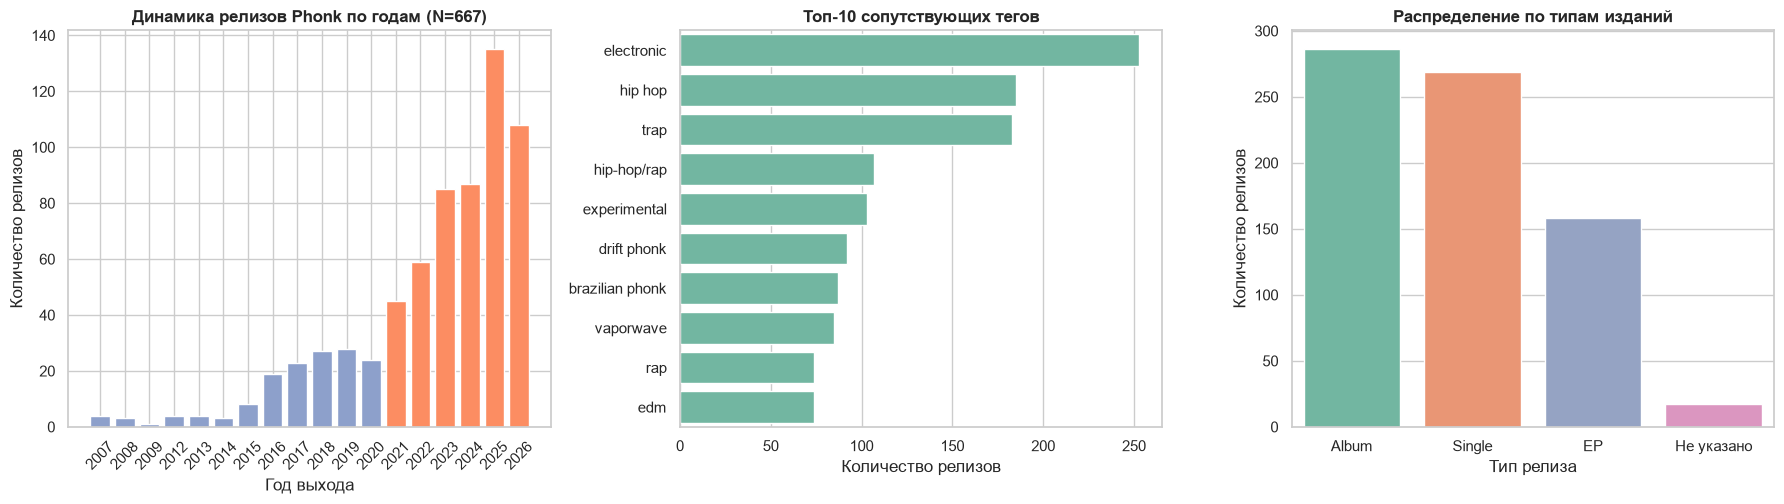

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

# 1. Динамика релизов по годам
year_counts = df["year"].dropna().astype(int).value_counts().sort_index()
colors_year = ["#8da0cb" if y < 2021 else "#fc8d62" for y in year_counts.index]

axes[0].bar(year_counts.index.astype(str), year_counts.values, color=colors_year)
axes[0].set_title("Динамика релизов Phonk по годам (N=667)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Год выхода")
axes[0].set_ylabel("Количество релизов")
axes[0].tick_params(axis="x", rotation=45)

# 2. Топ-10 сопутствующих тегов (исключая сам общий тег 'phonk')
tags_clean = tags_series[tags_series != "phonk"].value_counts().head(10)
sns.barplot(x=tags_clean.values, y=tags_clean.index, ax=axes[1], color="#66c2a5")
axes[1].set_title("Топ-10 сопутствующих тегов", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Количество релизов")
axes[1].set_ylabel("")

# 3. Типы релизов (Album, Single, EP)
type_counts = df["primary_type"].fillna("Не указано").value_counts()
sns.barplot(x=type_counts.index, y=type_counts.values, ax=axes[2], palette="Set2", hue=type_counts.index, legend=False)
axes[2].set_title("Распределение по типам изданий", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Тип релиза")
axes[2].set_ylabel("Количество релизов")

plt.tight_layout()
plt.savefig("phonk_analysis.png", dpi=150, bbox_inches="tight")
plt.show()